In [1]:
## Python Stuff
import os
import sys
import numpy as np
from array import array
import copy
import time
import matplotlib.pyplot as plt
import matplotlib

import uproot

os.environ.get("ROOTSYS")

""" run with:
jupyter lab --no-browser --log-level=ERROR --NotebookApp.open_browser=False --NotebookApp.allow_origin='*' --NotebookApp.ip='0.0.0.0'
in terminal
copy the address given into the kernel selection in vs code

or run directly in jupyter lab with the open notebook command
"""

" run with:\njupyter lab --no-browser --log-level=ERROR --NotebookApp.open_browser=False --NotebookApp.allow_origin='*' --NotebookApp.ip='0.0.0.0'\nin terminal\ncopy the address given into the kernel selection in vs code\n\nor run directly in jupyter lab with the open notebook command\n"

In [2]:
## ROOT stuff
import ROOT
from ROOT import TFile, TTree, TCanvas
from ROOT import TH1F, TH2F
import ctypes
import copy

ROOT.gStyle.SetCanvasDefW(600)
ROOT.gStyle.SetCanvasDefH(500)

# ROOT.gErrorIgnoreLevel = ROOT.kFatal
ROOT.gROOT.SetBatch(False)
# ROOT.enableJSVis()
# ROOT.disableJSVis()

opt = ROOT.Fit.DataOptions()

range1 = ROOT.Fit.DataRange()
range1.SetRange(0, 100)
testDF = ROOT.Fit.BinData(opt, range1)

Welcome to JupyROOT 6.27/01


In [34]:
sys.path.append(os.environ.get("CF4HOME")+"/code1Analysis/")
datPath = os.environ.get("CF4HOME")+"/code1Analysis/"
print(sys.path)

## Atown's stuff
from helpers.anaStructs import * # includes SORTING class/namespace
from helpers.getSPE import *
import helpers.graphBuilders as GB

['/Users/austindestcroix', '/Users/austindestcroix/packages/root_py311_v6_26.10/myInstall_p311/lib', '/Library/Frameworks/Python.framework/Versions/3.11/lib/python311.zip', '/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11', '/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/lib-dynload', '', '/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages', '/Users/austindestcroix/Desktop/school_holders/projects/sbc/CF4/code1Analysis/', '/Users/austindestcroix/Desktop/school_holders/projects/sbc/CF4/code1Analysis/']


In [4]:

## ------------- User Inputs ------------- ##
## USER INPUTS (kinda bad ngl) ##
NCHAN = 3
VERBOSE = False
ASK_MATPLOT = True
DO2D = False

# QVAR_USE = "qRCFlat"
# QVAR_USE = "qRCFixed"
QVAR_USE = "qFlat"
# QVAR_USE = "qFixed"
PECUTVALUE = 0.0

errorV = 0.05

## Paths to files, runLists
defPath = str(os.environ["CF4HOME"])+"/procData/" # where to get everything

In [5]:
## -------- physics and bkg runs -------- ##
bkgVoltagePath = "runLists/analysis1/"       # bkg run list files
bkgVoltageRuns = np.loadtxt(defPath + bkgVoltagePath + "bkg_voltage_runs.txt", dtype=int).tolist()
bkgVoltages = np.loadtxt(defPath + bkgVoltagePath + "bkg_voltage_list.txt", dtype=int).tolist()

# final inputs into code
allRuns = bkgVoltageRuns
allRuns

[202204141206,
 202204141158,
 202204141138,
 202204141143,
 202204141147,
 202204141151,
 202204141154]

In [6]:
## Get all RC objects ##
rcList = [] ## everything from here
fList = []

speList = []
chi2list = []

# loading data and SPE analysis
# everything is in rcList
for run in allRuns:
  fpath = defPath + "analysis1/npv1_" + str(run) + ".root"
  f = ROOT.TFile(fpath, "READ") #file opens
  fList.append(f) # NEED THIS to keep ttrees persistent (all reference in Python)


  tt = f.Get("tt")
  rcObj = RunClass(run, tt, fname = fpath)
  rcObj.assign_voltage(allRuns, bkgVoltages)

  rcObj.computeSPE(width = 15, verbose=VERBOSE, varname=QVAR_USE, channels = [i for i in range(NCHAN)], nbins = 150, specialCase = rcObj.id)
  rcObj.print()

  rcObj.UprootConstructor()
  rcList.append(rcObj)

  for chan in rcObj.mChannels:
    # print(chan.mSpe.chi2)
    speList.append(chan.mSpe.spe)
    chi2list.append(chan.mSpe.chi2)


runID: 202204141206
Nevents: 11213.00,   time: 8.54 min
average Rate: 21.88 Hz
chID:0: spe = 78.89 +/- 0.32     maxChi2 = 10.29
chID:1: spe = 85.81 +/- 0.52     maxChi2 = 84.71
chID:2: spe = 85.42 +/- 0.51     maxChi2 = 39.22

runID: 202204141158
Nevents: 10163.00,   time: 5.27 min
average Rate: 32.14 Hz
chID:0: spe = 115.36 +/- 0.55     maxChi2 = 16.31
chID:1: spe = 121.16 +/- 0.78     maxChi2 = 12.42
chID:2: spe = 121.05 +/- 0.57     maxChi2 = 20.05

runID: 202204141138
Nevents: 10089.00,   time: 4.58 min
average Rate: 36.69 Hz
chID:0: spe = 150.51 +/- 0.47     maxChi2 = 21.23
chID:1: spe = 156.52 +/- 0.98     maxChi2 = 11.41
chID:2: spe = 158.15 +/- 0.68     maxChi2 = 21.91

runID: 202204141143
Nevents: 10190.00,   time: 3.95 min
average Rate: 42.99 Hz
chID:0: spe = 183.98 +/- 0.60     maxChi2 = 11.31
chID:1: spe = 189.64 +/- 0.92     maxChi2 = 16.92
chID:2: spe = 191.45 +/- 0.92     maxChi2 = 11.94

runID: 202204141147
Nevents: 10275.00,   time: 3.97 min
average Rate: 43.18 Hz
chI

Warning in <TSpectrum::SearchHighRes>: Peak buffer full
Info in <TCanvas::MakeDefCanvas>:  created default TCanvas with name c1
Warning in <TSpectrum::SearchHighRes>: Peak buffer full
Warning in <TSpectrum::SearchHighRes>: Peak buffer full
Warning in <TSpectrum::SearchHighRes>: Peak buffer full
Warning in <TSpectrum::SearchHighRes>: Peak buffer full
Warning in <TSpectrum::SearchHighRes>: Peak buffer full
Warning in <TSpectrum::SearchHighRes>: Peak buffer full
Warning in <TSpectrum::SearchHighRes>: Peak buffer full
Warning in <TSpectrum::SearchHighRes>: Peak buffer full
Warning in <TSpectrum::SearchHighRes>: Peak buffer full
Warning in <TSpectrum::SearchHighRes>: Peak buffer full
Warning in <TSpectrum::SearchHighRes>: Peak buffer full
Warning in <TSpectrum::SearchHighRes>: Peak buffer full
Warning in <TSpectrum::SearchHighRes>: Peak buffer full
Warning in <TSpectrum::SearchHighRes>: Peak buffer full
Warning in <TSpectrum::SearchHighRes>: Peak buffer full
Warning in <TSpectrum::SearchHig

In [7]:
for rc in rcList:
  f = uproot.open(rc.mFname)
  tt = f["tt"]
  rc.mTimes = tt

In [54]:
rcList[0].tt.Show(0)
FindRCbyVoltage = lambda V, rclist: next((rc for rc in rclist if rc.mVoltage == V), None)

# rc52 = FindRCbyVoltage(52, rcList)
# rc52.print()

# c = TCanvas()

# print(rc52.mChannels[0].mSpe.mRawHist.GetEntries())
# rc52.mChannels[0].mSpe.mRawHist.Draw("hist")

# c.SetLogy()
# c.Draw()
# c.Update()

======> EVENT:0
 chInfo          = 0, 
                  0, 0
 evTime          = 839511
 blineV          = 2113, 
                  2113, 2113
 blineE          = 2113, 
                  2113, 2113
 minV            = 2111, 
                  2111, 2101
 timeMin         = 48, 
                  608, 1200
 qFixed          = 7, 
                  12, 95
 qFlat           = 0, 
                  0, 93
 tFlatStart      = 0, 
                  0, 1056
 tFlatEnd        = 0, 
                  0, 1440
 qRCFixed        = 0, 
                  0, 110.681
 qRCFlat         = 0, 
                  0, 99.8756


[[0.05 0.05 0.05]
 [0.05 0.05 0.05]
 [0.05 0.05 0.05]
 [0.05 0.05 0.05]
 [0.05 0.05 0.05]
 [0.05 0.05 0.05]
 [0.05 0.05 0.05]]


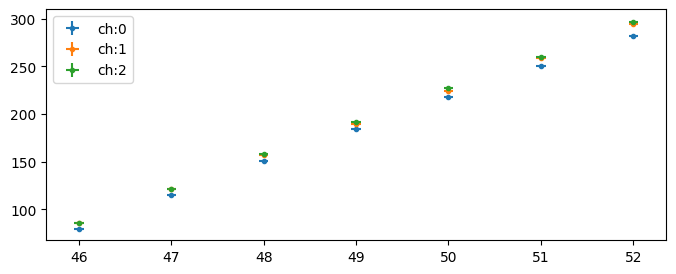

In [9]:
## checking SPE values and errors
## calculating Vbreakdown as well
speFig, speAxes = plt.subplots(1, 1, figsize = (8, 3))

ax = speAxes

ySPE = np.array([[rc.GetSPE(ich) for ich in range(NCHAN)] for rc in rcList], dtype=np.float64)
yeSPE = np.array([[rc.GetChan(ich).mSpe.espe for ich in range(NCHAN)] for rc in rcList], dtype=np.float64)
xVoltage = np.array([[rc.mVoltage for ich in range(NCHAN)] for rc in rcList], dtype=np.float64)
xeV_long = np.array([[errorV for ich in range(NCHAN)] for rc in rcList], dtype=np.float64)
print(xeV_long)

xV = np.array(xVoltage[:, 0], dtype = np.float64)
xeV = np.repeat(errorV, len(xV))

for ich in range(NCHAN):
  ax.errorbar(xVoltage[:,ich], ySPE[:,ich], xerr = xeV, yerr = yeSPE[:,ich], marker = ".", linestyle = "", label = "ch:" +str(ich))
# ax.set_yscale("log")

plt.legend()
plt.show()


In [10]:
## doing multifit the annoying ROOT way
### starting from 'combinedFit.py' example
tgList = []
ySPElist = []
yeSPElist = [] # tracking data for tgraphs

for ich in range(NCHAN):
  ydata = np.array(ySPE[:,ich], dtype=np.float64)
  yerr = np.array(yeSPE[:,ich], dtype=np.float64)

  ySPElist.append(ydata)
  yeSPElist.append(yerr)

  tg1 = ROOT.TGraphErrors(len(xV), xV, ydata, xeV, yerr)
  tgList.append(tg1)

# starting multifit
ipar1 = np.array([0, 1], dtype=np.int32) # shared slope and breakdown voltage 1
ipar2 = np.array([0, 2], dtype=np.int32)
ipar3 = np.array([0, 3], dtype=np.int32) # shared slope and breakdown voltage 2

class GlobalChi2(object):
  def __init__(self, f1, f2, f3):
    self._f1 = f1
    self._f2 = f2
    self._f3 = f3
    return

  def __call__(self, par):
    # the zero-copy way to get a numpy array from a double *
    par_arr = np.frombuffer(par, dtype=np.float64, count=-1)

    p1 = par_arr[ipar1]
    p2 = par_arr[ipar2]
    p3 = par_arr[ipar3]

    return self._f1(p1) + self._f2(p2) + self._f3(p3)

fl1 = ROOT.TF1("fl1", "[0]*(x - [1])", 40., 60.)
wf1 = ROOT.Math.WrappedMultiTF1(fl1, 1)

opt = ROOT.Fit.DataOptions()

range1 = ROOT.Fit.DataRange()
range1.SetRange(0, 100)
testDF = ROOT.Fit.BinData(opt, range1)
dataFit = [ROOT.Fit.BinData(opt, range1), ROOT.Fit.BinData(opt, range1), ROOT.Fit.BinData(opt, range1)]

for ich in range(NCHAN):
  ROOT.Fit.FillData(dataFit[ich], tgList[ich])

chi1 = ROOT.Fit.Chi2Function(dataFit[0], wf1)
chi2 = ROOT.Fit.Chi2Function(dataFit[1], wf1)
chi3 = ROOT.Fit.Chi2Function(dataFit[2], wf1)
globalChi2 = GlobalChi2(chi1, chi2, chi3)

fitter = ROOT.Fit.Fitter()

par0 = np.array([35, 43, 43, 43], dtype=np.float64)
buffpar0 = np.frombuffer(par0, dtype=np.float64, count=-1)

fitter.Config().SetParamsSettings(4, buffpar0)
fitter.Config().MinimizerOptions().SetPrintLevel(0)
fitter.Config().SetMinimizer("Minuit2", "Migrad")

globalChi2Functor = ROOT.Math.Functor(globalChi2, 4)

# # fit FCN function
# # (specify optionally data size and flag to indicate that is a chi2 fit)
fitter.FitFCN(globalChi2Functor, 0, NCHAN*dataFit[0].Size(), True)
result = fitter.Result()
result.Print(ROOT.std.cout)


****************************************
Minimizer is Minuit2 / Migrad
Chi2                      =      12.3903
NDf                       =           17
Edm                       =  9.35738e-06
NCalls                    =           99
Par_0                     =      34.3906   +/-   0.219695    
Par_1                     =      43.6871   +/-   0.0386524   
Par_2                     =      43.4768   +/-   0.0402029   
Par_3                     =      43.4474   +/-   0.0389481   


In [11]:
print(result.Parameters())
vbr0 = [result.Parameters()[1], result.ParError(1)]
vbr1 = [result.Parameters()[2], result.ParError(2)]
vbr2 = [result.Parameters()[3], result.ParError(3)]
slopeSPE = [result.Parameters()[0], result.ParError(0)]
vbrList = [vbr0, vbr1, vbr2]

line = lambda x, m, vbr: m * (x - vbr)

{ 34.390650, 43.687066, 43.476779, 43.447439 }


 FCN=90.0997 FROM MIGRAD    STATUS=CONVERGED     193 CALLS         194 TOTAL
                     EDM=1.29496e-07    STRATEGY= 1      ERROR MATRIX ACCURATE 
  EXT PARAMETER                                   STEP         FIRST   
  NO.   NAME      VALUE            ERROR          SIZE      DERIVATIVE 
   1  p0           3.43525e+01   2.19492e-01   3.61123e-04  -2.09112e-03
   2  p1           4.35408e+01   3.50853e-02   5.77318e-05  -1.51054e-03


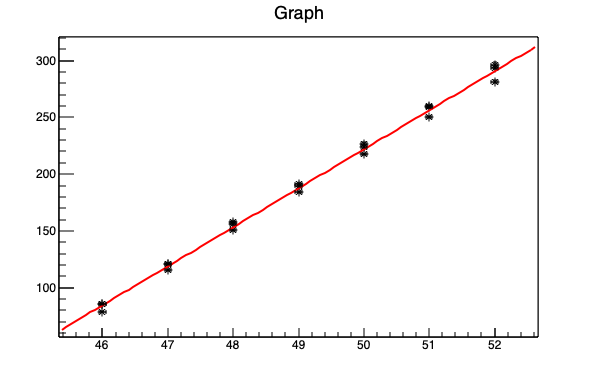

In [12]:
# line(xVoltage[:,0], slopeSPE, vbrList[0][0])
totalSPEGraph = ROOT.TGraphErrors(len(xeV_long.flatten()), xVoltage.flatten(), ySPE.flatten(), xeV_long.flatten(), yeSPE.flatten())
fl_total = ROOT.TF1("fl_total", "[0]*(x - [1])")

totalSPEGraph.Fit("fl_total", "", "", 30., 60)
vGlobal = fl_total.GetParameters()[1]
vEglobal = fl_total.GetParErrors()[1]
vSlopeGlobal = fl_total.GetParameters()[0]

c1 = TCanvas("cwhat", "cwhat", 600, 400)
totalSPEGraph.Draw("AE*")

c1.Update()
c1.Draw()

Operational Vover = 4.46


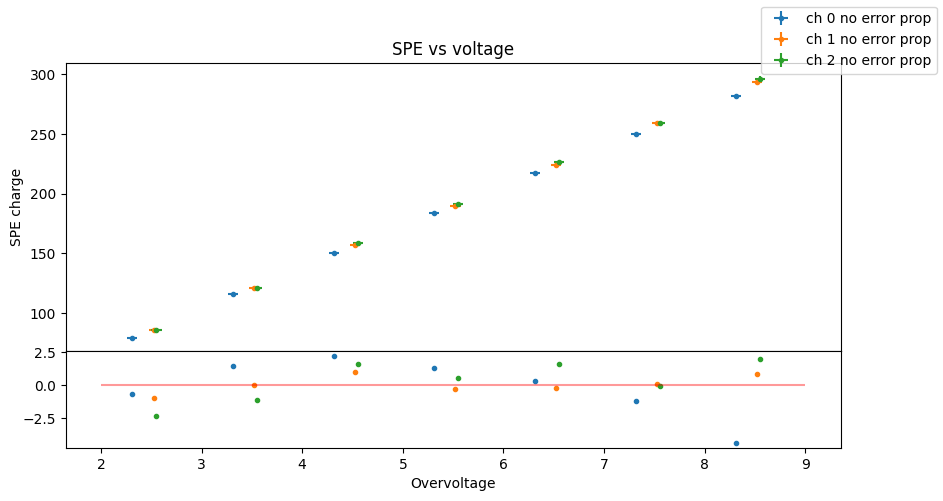

In [26]:
## checking SPE values and errors
## calculating Vbreakdown as well
speFig, (speAxes, resAx) = plt.subplots(2, 1, figsize = (10, 5), sharex = True, gridspec_kw={'height_ratios': [3, 1]})

for ich in range(NCHAN):
  xOverV = xVoltage[:,ich] - vbrList[ich][0]
  speAxes.errorbar(xOverV, ySPE[:,ich], xerr = xeV, yerr = yeSPE[:,ich], marker = ".", linestyle = "", label = f"ch {ich} no error prop")
  resAx.plot(xOverV, ySPE[:,ich] - line(xVoltage[:,ich], slopeSPE[0], vbrList[ich][0]), ".")

# ax.set_yscale("log")
speAxes.set_title("SPE vs voltage")
speAxes.set_ylabel("SPE charge")

resAx.set_xlabel("Overvoltage")
# resAx.set_ylim(-5, 5)

xOverV = xVoltage[:,0] - vGlobal
# speAxes.plot(xOverV, vSlopeGlobal * (xOverV))

resAx.hlines(0, 2, 9, color = "red", alpha = 0.4)

# plt.tight_layout(pad=0)
speFig.legend()
plt.subplots_adjust(hspace=.0)

print(f"Operational Vover = {48 - vGlobal:0.2f}")
plt.show()

In [14]:
# printing information
# rcList[0].tt.Show(0)
# for rc in rcList:
#   rc.print()

######## Building Full Spectra ########
binLow = -0.5
binHigh = 19.5
Nbins = 200.
binWidth = (binHigh - binLow) / Nbins
hReference = TH1F("hReference", "hReference", int(Nbins), binLow, binHigh) # histogram that everything is built off
hReference.Sumw2(True)

# building all SPE spectra
for rc in rcList:
  rc.BuildSpectrum(hReference, QVAR_USE, PECUTVALUE, rate = True)
  rc.setup_forComparison()

## Time between events for one run
# hTimeBetweenEvents = TH1F("hTimeBetweenEvents", "hTimeBetweenEvents", 100, 0., 0.2)
# for rc in rcl_Bkg_0310:
#   rc.BuildTTNE(hTimeBetweenEvents)

done filling histogram: hNPE_202204141206
done filling histogram: hNPE_202204141158
done filling histogram: hNPE_202204141138
done filling histogram: hNPE_202204141143
done filling histogram: hNPE_202204141147
done filling histogram: hNPE_202204141151
done filling histogram: hNPE_202204141154


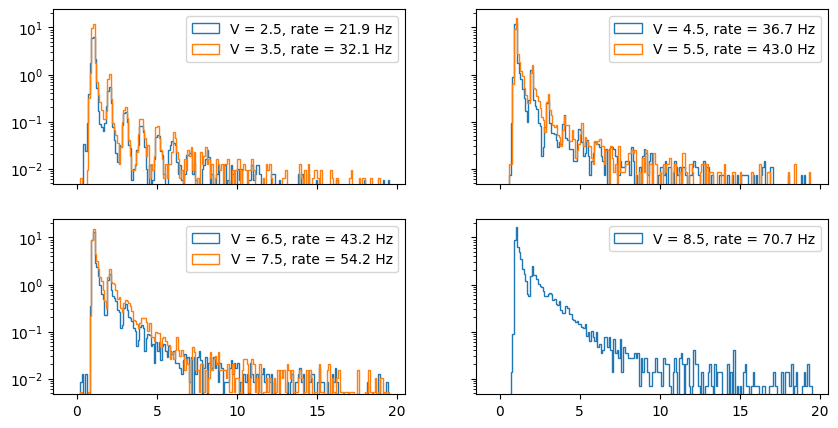

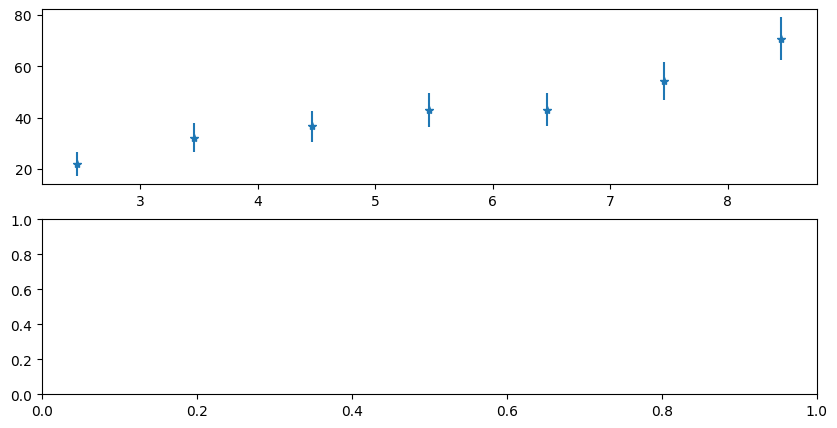

In [15]:
fig, axes = plt.subplots(2, 2, figsize = (10, 5), sharex = True, sharey=True)
axes = axes.flatten()
for rc in rcList:
  ax = axes[int(rcList.index(rc)//2)]
  rc.mpl_hist(ax, True, histtype = "step", label = f"V = {rc.mVoltage - vGlobal:0.1f}, rate = {rc.GetRate():0.1f} Hz")
  ax.set_yscale("log")
  ax.legend()

fig, axes = plt.subplots(2, 1, figsize =(10, 5))
rates = np.array([rc.GetRate() for rc in rcList])
axes[0].errorbar(xOverV, rates, yerr = np.sqrt(rates), marker = "*", linestyle = "None")
plt.show()

In [66]:
datV, datCA = np.loadtxt(datPath+ "/giacomoNoise_newVUV4.txt", delimiter=",", skiprows=1, unpack = True)
datV2, datCA2 = np.loadtxt(datPath+ "/giacomoNoise_oldVUV4.txt", delimiter=",", skiprows=1, unpack = True)


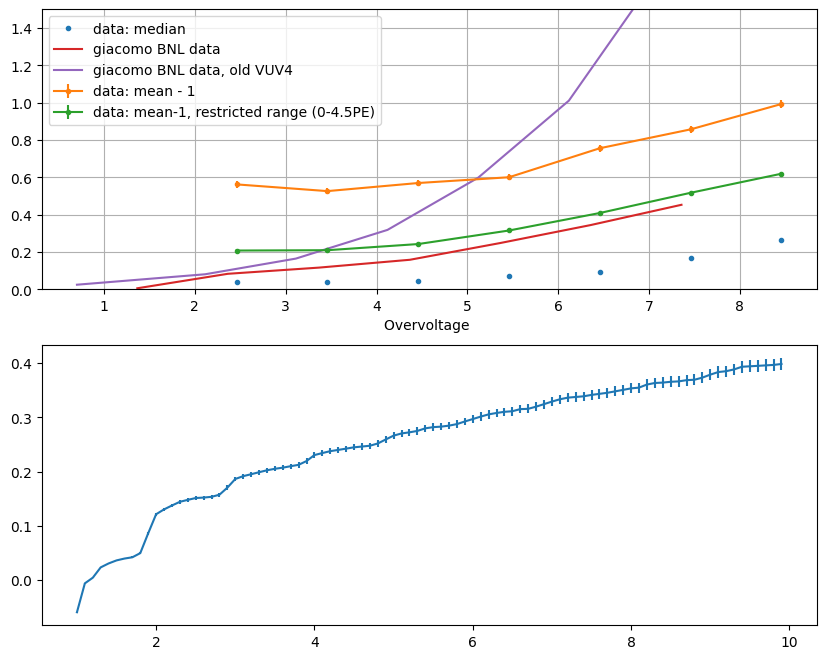

In [69]:

nCA_median = []
nCA_mean = []
nCA_mean_restricted = []
# xOverV

for rc in rcList:
  hs = rc.GetSpectrum()
  hs.GetXaxis().SetRange() # reset just in case
  q = np.array([0.5], dtype=np.float64)
  median = np.array([0.], dtype=np.float64)
  hs.GetQuantiles(1, median, q)
  nCA_median.append(median[0] - 1.)

  nCA_mean.append([hs.GetMean() - 1., hs.GetMeanError()])
  hs.GetXaxis().SetRangeUser(0., 4.5)
  nCA_mean_restricted.append([hs.GetMean() - 1., hs.GetMeanError()])
  # print(mean)
nCA_median = np.array(nCA_median)
nCA_mean_restricted = np.array(nCA_mean_restricted)
nCA_mean = np.array(nCA_mean)

# nCA vs mean range
xMeanEndRange = np.arange(1.0, 10, 0.1)
rc48 = FindRCbyVoltage(48, rcList)
hs = rc48.GetSpectrum()
# rc48.print()
nCA_meanVsRange = []
for x in xMeanEndRange:
  hs.GetXaxis().SetRangeUser(0, x)
  nCA_meanVsRange.append([hs.GetMean()-1, hs.GetMeanError()])
nCA_meanVsRange = np.array(nCA_meanVsRange)

## plotting 
fig, (ax, ax2) = plt.subplots(2, 1, figsize = (10, 8))
ax.plot(xOverV, nCA_median, ".", label = "data: median")
ax.errorbar(xOverV, nCA_mean[:, 0],yerr = nCA_mean[:, 1],  marker = ".", label = "data: mean - 1")
ax.errorbar(xOverV, nCA_mean_restricted[:, 0], yerr = nCA_mean_restricted[:, 1], marker = ".", label = "data: mean-1, restricted range (0-4.5PE)")

ax.plot(datV, datCA, label = "giacomo BNL data")
ax.plot(datV2, datCA2, label = "giacomo BNL data, old VUV4")

ax.set_xlabel("Overvoltage ")
ax.set_ylim(0, 1.5)

ax.legend()
ax.grid()

ax2.errorbar(xMeanEndRange, nCA_meanVsRange[:, 0], yerr = nCA_meanVsRange[:, 1])
plt.show()

# this figure is:
# bkg * PDE --> mean up
# 1PE backgrounds --> mean down
# ratio of 1PE DN to background --> drive mean down
# 2PE backgrounds --> drive mean up

In [17]:
a = np.array([[10, 11, 10], [11, 15, 20]])
b = np.array([1, 2, 3])
a/b
a.shape
mask = a > 10
# np.sum(a, axis=1)
# np.min(a, axis = 1)
print(mask)
a * mask


[[False  True False]
 [ True  True  True]]


array([[ 0, 11,  0],
       [11, 15, 20]])

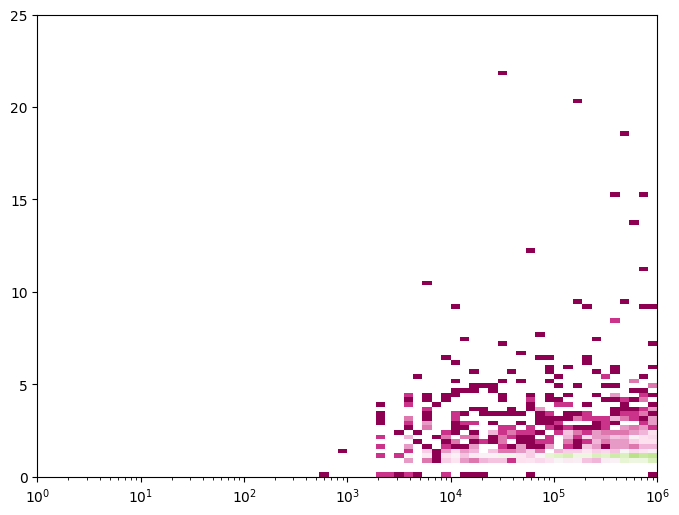

In [25]:
rc = rcList[6]

rc.BuildCorrectEventTimes()
timePulses, NPElist = rc.BuildCorrectEventPulseTimes(QVAR_USE, peCut=0.5)

ttnp = (timePulses[1:] - timePulses[:-1]) # currently in ns
NPElist2 = NPElist[1:]

x_edges = np.logspace(-1, 8, num = 100)
y_edges = np.linspace(0, 25, num = 100)
# plt.hist(evTime, bins = 500, range = (0, int(max(evTime))), histtype="step")
# plt.hist(evTimeFixed, bins = 500, range = (0, max(evTimeFixed)))
# plt.plot()
# plt.hist(ttnp, bins = 100)
fig, ax = plt.subplots(1, 1, figsize =(8, 6))
ax.hist2d(ttnp, NPElist2, bins = [x_edges, y_edges], cmap = "PiYG", norm = matplotlib.colors.LogNorm())
# plt.hist2d(NPElist[:-1], NPElist[1:], bins = (100, 100), range=((0, 10), (0, 10)), cmap = "PiYG", norm = matplotlib.colors.LogNorm())
ax.set_xlim(1, 10**6)
ax.set_xscale("log")

plt.show()
